The general equation for an ellipse is

$$
\frac{(x-h)\cos(\theta) + (y-k)\sin(\theta)}{a^2} + 
\frac{(x-h)\sin(\theta) - (y-k)\cos(\theta)}{b^2} = 1
$$

where 
($x$,$y$) are points on the ellipse, 
($h$,$k$) is the center of the ellipse,
$a$ and $b$ are the axes of the ellipse,
and
$\theta$ is the rotation angle measured from the $x$-axis.

Find the minimum distance between two ellipses with the following parameters:

| Parameter | 1      | 2      |
| :-------- | :----: | -----: |
| $a$       | 12.1   | 5.3    |
| $b$       | 4.2    | 3.1    |
| $\theta$  | 28.3°  | 110.4° |
| $h$       | -2.7   | 8.1    |
| $k$       | 5.6    | 2.9    |

Plot the ellipses and the line connecting them at the shortest distance.

Hint: I think it's easier to plot the ellipses using the parameterized equations

$$
x(t) = a \cos(t)\cos(\theta) - b \sin(t)\sin(\theta) + h \\
y(t) = b \cos(t)\sin(\theta) + b \sin(t)\cos(\theta) + k
$$

where $t$ is the parameter, $0 \le t \lt 2\pi$.

Sample output, for a different problem, is

```
Minimum Distance: 7.70
```

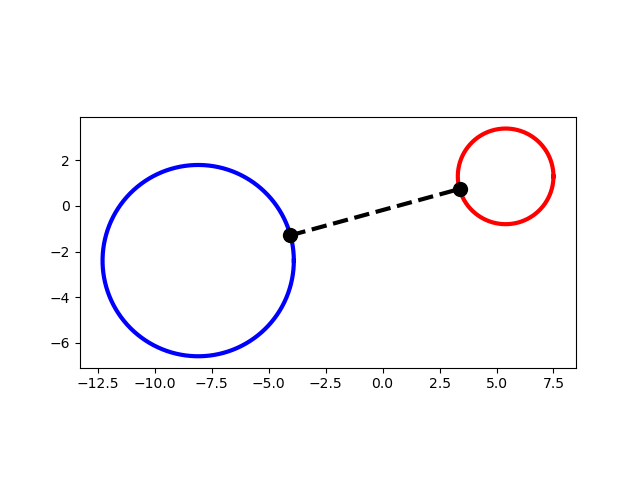

Minimum Distance: 3.5960


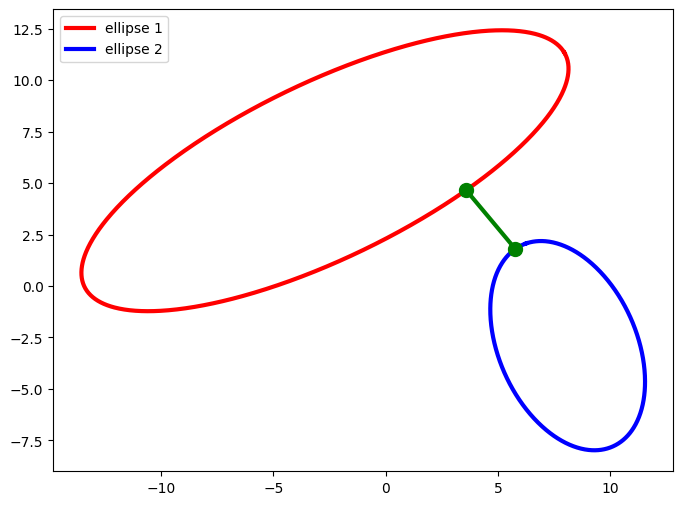

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt

# unit conversion

degrees_to_radians = np.pi/180  

#ellipse parameters

a1,a2 = 12.1,5.3
b1,b2 = 4.2,3.1
theta1,theta2 = 28.3*degrees_to_radians,110.4*degrees_to_radians
h1,h2 = -2.7, 8.1  
k1,k2 = 5.6, -2.9

def x(a,b,theta,h,t):
    return a*np.cos(t)*np.cos(theta) - b*np.sin(t)*np.sin(theta)+h

def y(a,b,theta,k,t):
    return a*np.cos(t)*np.sin(theta) + b*np.sin(t)*np.cos(theta)+k

t = np.linspace(0,2*np.pi,1000)

x1 = x(a1,b1,theta1,h1,t)
y1 = y(a1,b1,theta1,k1,t)

x2 = x(a2,b2,theta2,h2,t)
y2 = y(a2,b2,theta2,k2,t)

# distance between two points

def distance(t):  # distance squared
    t1,t2 = t
    x1 = x(a1,b1,theta1,h1,t1)
    y1 = y(a1,b1,theta1,k1,t1)

    x2 = x(a2,b2,theta2,h2,t2)
    y2 = y(a2,b2,theta2,k2,t2)

    return (x2-x1)**2 + (y2-y1)**2

plt.figure(figsize=(8,6))
plt.plot(x1,y1,lw=3,color='r',label='ellipse 1')
plt.plot(x2,y2,lw=3,color='b',label='ellipse 2')
plt.legend()

soln = opt.minimize(distance,[1,1],bounds=[(0,2*np.pi),(0,2*np.pi)])
soln_t1,soln_t2 = soln.x

x1 = x(a1,b1,theta1,h1,soln_t1)
y1 = y(a1,b1,theta1,k1,soln_t1)

x2 = x(a2,b2,theta2,h2,soln_t2)
y2 = y(a2,b2,theta2,k2,soln_t2) 

plt.plot([x1,x2],[y1,y2],'o',ms=10,color='g')
plt.plot([x1,x2],[y1,y2],lw=3,color='g')

min_distance = np.sqrt((x2-x1)**2 + (y2-y1)**2)

print(f"Minimum Distance: {min_distance:.4f}")
